# ATP tennis network
## Tasks 1 and 2 · IE University

We built an adjacency matrix and a transition matrix from the ATP tennis dataset. We then examined the original match graph, made a prediction about which player would rank highly, and chose two starting players for Task 3.

### Setup

This notebook runs from the root of the full project repository using the project's .venv Python environment. It imports helper functions from the src folder.

In [1]:
import sys
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, display

In [2]:
project_dir = Path.cwd()
source_dir = project_dir / "src"
data_dir = project_dir / "data"

if not (source_dir / "task1_2_helpers.py").is_file():
    raise FileNotFoundError("Open the notebook from the root of Computer-Programming-I-Project.")
if str(source_dir) not in sys.path:
    sys.path.insert(0, str(source_dir))

### Import project functions

In [3]:
from task1_2_helpers import (
    build_adjacency,
    build_transition,
    inspect_components,
    load_tennis_data,
    plot_outgoing_row,
)
from task3 import STARTING_PLAYERS

## Task 1 · From tennis results to a transition matrix

### Read the data and fix the player order

Each node represents a player. An arrow from player i to player j means i lost to j at least once in the supplied 2016–2025 tour-level results. Repeat wins in the same direction collapse into one edge. The dataset contains **1,191 players and 19,986 directed edges**. We use the supplied node IDs, from 0 to 1,190, as row and column indices in both matrices and in the tables.

In [4]:
nodes, edges = load_tennis_data(data_dir)
n = len(nodes)
player_names = nodes.set_index("node_id")["label"]
player_ids = dict(zip(nodes["label"], nodes["node_id"]))

print(f"{n:,} players and {len(edges):,} directed edges")
display(nodes[["node_id", "label"]].head())
display(edges.head())

1,191 players and 19,986 directed edges


,node_id,label
0,0,Alexander Zverev
1,1,Martin Damm
2,2,Nenad Zimonjic
3,3,Tommy Haas
4,4,Radek Stepanek


,source,target
0,0,20
1,0,28
2,0,30
3,0,32
4,0,42


In [5]:
# Check that the sorted player IDs can be used as matrix indices.
assert np.array_equal(nodes["node_id"].to_numpy(), np.arange(n)), "Player IDs must be consecutive from 0 to n − 1."
print("Pass: player order matches the matrix indices.")

Pass: player order matches the matrix indices.


In [6]:
# Check that each arrow refers to valid players.
endpoints = edges[["source", "target"]].to_numpy()
assert np.all((0 <= endpoints) & (endpoints < n)), "An edge refers to a player ID outside the matrix."
print("Pass: every arrow endpoint is a valid player ID.")

Pass: every arrow endpoint is a valid player ID.


### Build the adjacency matrix A

We put a 1 in A[i, j] when there is a match arrow from i to j and a 0 otherwise. The row refers to the loser and the column to the winner. Summing a row gives that player's out-degree, the number of different opponents who beat them.

In [7]:
A = build_adjacency(n, edges)
print(f"Adjacency matrix shape: {A.shape}")

Adjacency matrix shape: (1191, 1191)


In [8]:
# Each directed edge should be represented by a single 1.
assert A.sum() == len(edges), "The adjacency matrix does not represent every supplied edge exactly once."
print(f"Pass: A contains {A.sum():,} directed links.")

Pass: A contains 19,986 directed links.


### Build the completed transition matrix P

For a player with out-degree d > 0, we divide every entry in their row of A by d. This gives every recorded outgoing arrow equal probability. A dangling player has zero outgoing arrows, so the original row offers no next move. We give every player probability 1/1191 in that row, allowing the walk to continue without favoring any destination. We divide by d only for rows with d > 0.

In [9]:
P, out_degree, dangling = build_transition(A)
print(f"Transition matrix shape: {P.shape}")
print(f"Dangling players: {np.count_nonzero(dangling)}")

Transition matrix shape: (1191, 1191)
Dangling players: 63


### Check that P represents probabilities

Each entry must be nonnegative because a move cannot have negative probability. The total across a row must be one because the walker makes one of the available moves. We check these properties in separate cells.

In [10]:
assert np.all(P >= 0), "P contains a negative or invalid transition probability."
print("Pass: all transition probabilities are nonnegative.")

Pass: all transition probabilities are nonnegative.


In [11]:
row_sums = P.sum(axis=1)
bad_rows = np.flatnonzero(~np.isclose(row_sums, 1, atol=1e-12, rtol=0))
assert bad_rows.size == 0, f"These P rows do not sum to 1: {bad_rows[:5]}"
print("Pass: every row sums to 1 within numerical tolerance.")

Pass: every row sums to 1 within numerical tolerance.


In [12]:
assert np.allclose(P[dangling], 1 / n, atol=1e-12, rtol=0), "A dangling row is not uniform."
print("Pass: each dangling row assigns 1/1191 to every destination.")

Pass: each dangling row assigns 1/1191 to every destination.


### Show labelled matrix extracts and a row by hand

The full matrices are 1,191 by 1,191, so we show selected rows and columns in node ID order. Martin Damm (ID 1) lost to Christopher O'Connell (ID 411) and Frances Tiafoe (ID 589). Those are the two ones in his row of A, so his out-degree is 2.

    P[1, 411] = A[1, 411] / 2 = 1/2
    P[1, 589] = A[1, 589] / 2 = 1/2

Every other entry in Damm's row is zero. The other example row belongs to Rohan Bopanna (ID 8). It is zero in A and uniform in P. The P extract displays rounded probabilities.

In [13]:
row_ids = [1, 8]
column_ids = [0, 411, 589]
row_labels = [f"{i} · {player_names[i]}" for i in row_ids]
column_labels = [f"{i} · {player_names[i]}" for i in column_ids]
for label, matrix in [("A — match arrows", A), ("P — transition probabilities", P)]:
    print(label)
    extract = pd.DataFrame(matrix[np.ix_(row_ids, column_ids)], index=row_labels, columns=column_labels)
    extract.index.name = "From player"
    extract.columns.name = "To player"
    display(extract.round(6))

A — match arrows


To player,0 · Alexander Zverev,411 · Christopher Oconnell,589 · Frances Tiafoe
From player,,,
1 · Martin Damm,0,1,1
8 · Rohan Bopanna,0,0,0


P — transition probabilities


To player,0 · Alexander Zverev,411 · Christopher Oconnell,589 · Frances Tiafoe
From player,,,
1 · Martin Damm,0.00000,0.50000,0.50000
8 · Rohan Bopanna,0.00084,0.00084,0.00084


In [14]:
damm = player_ids["Martin Damm"]
expected_damm_row = np.zeros(n)
expected_damm_row[[411, 589]] = 0.5
assert np.array_equal(P[damm], expected_damm_row), "Damm's computed row differs from the hand calculation."
print("Pass: the complete Damm row matches the worked example.")

Pass: the complete Damm row matches the worked example.


### Visualize the match arrows

The first figure shows Damm's row as a directed subgraph. The second is the project's view of the largest strongly connected component. That figure omits arrowheads for readability. The calculations use the full directed graph.

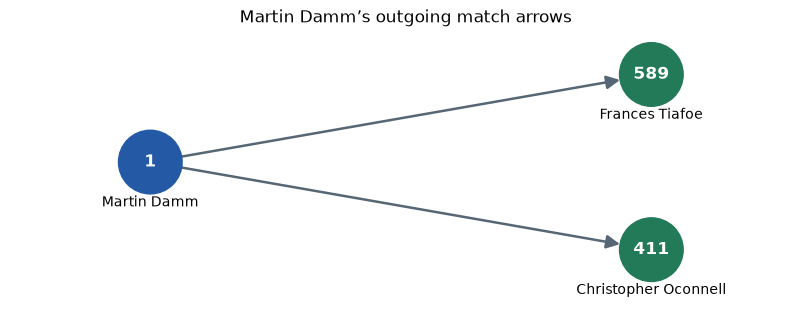

In [15]:
damm_figure = plot_outgoing_row(A, player_names, damm)
display(damm_figure)
plt.close(damm_figure)

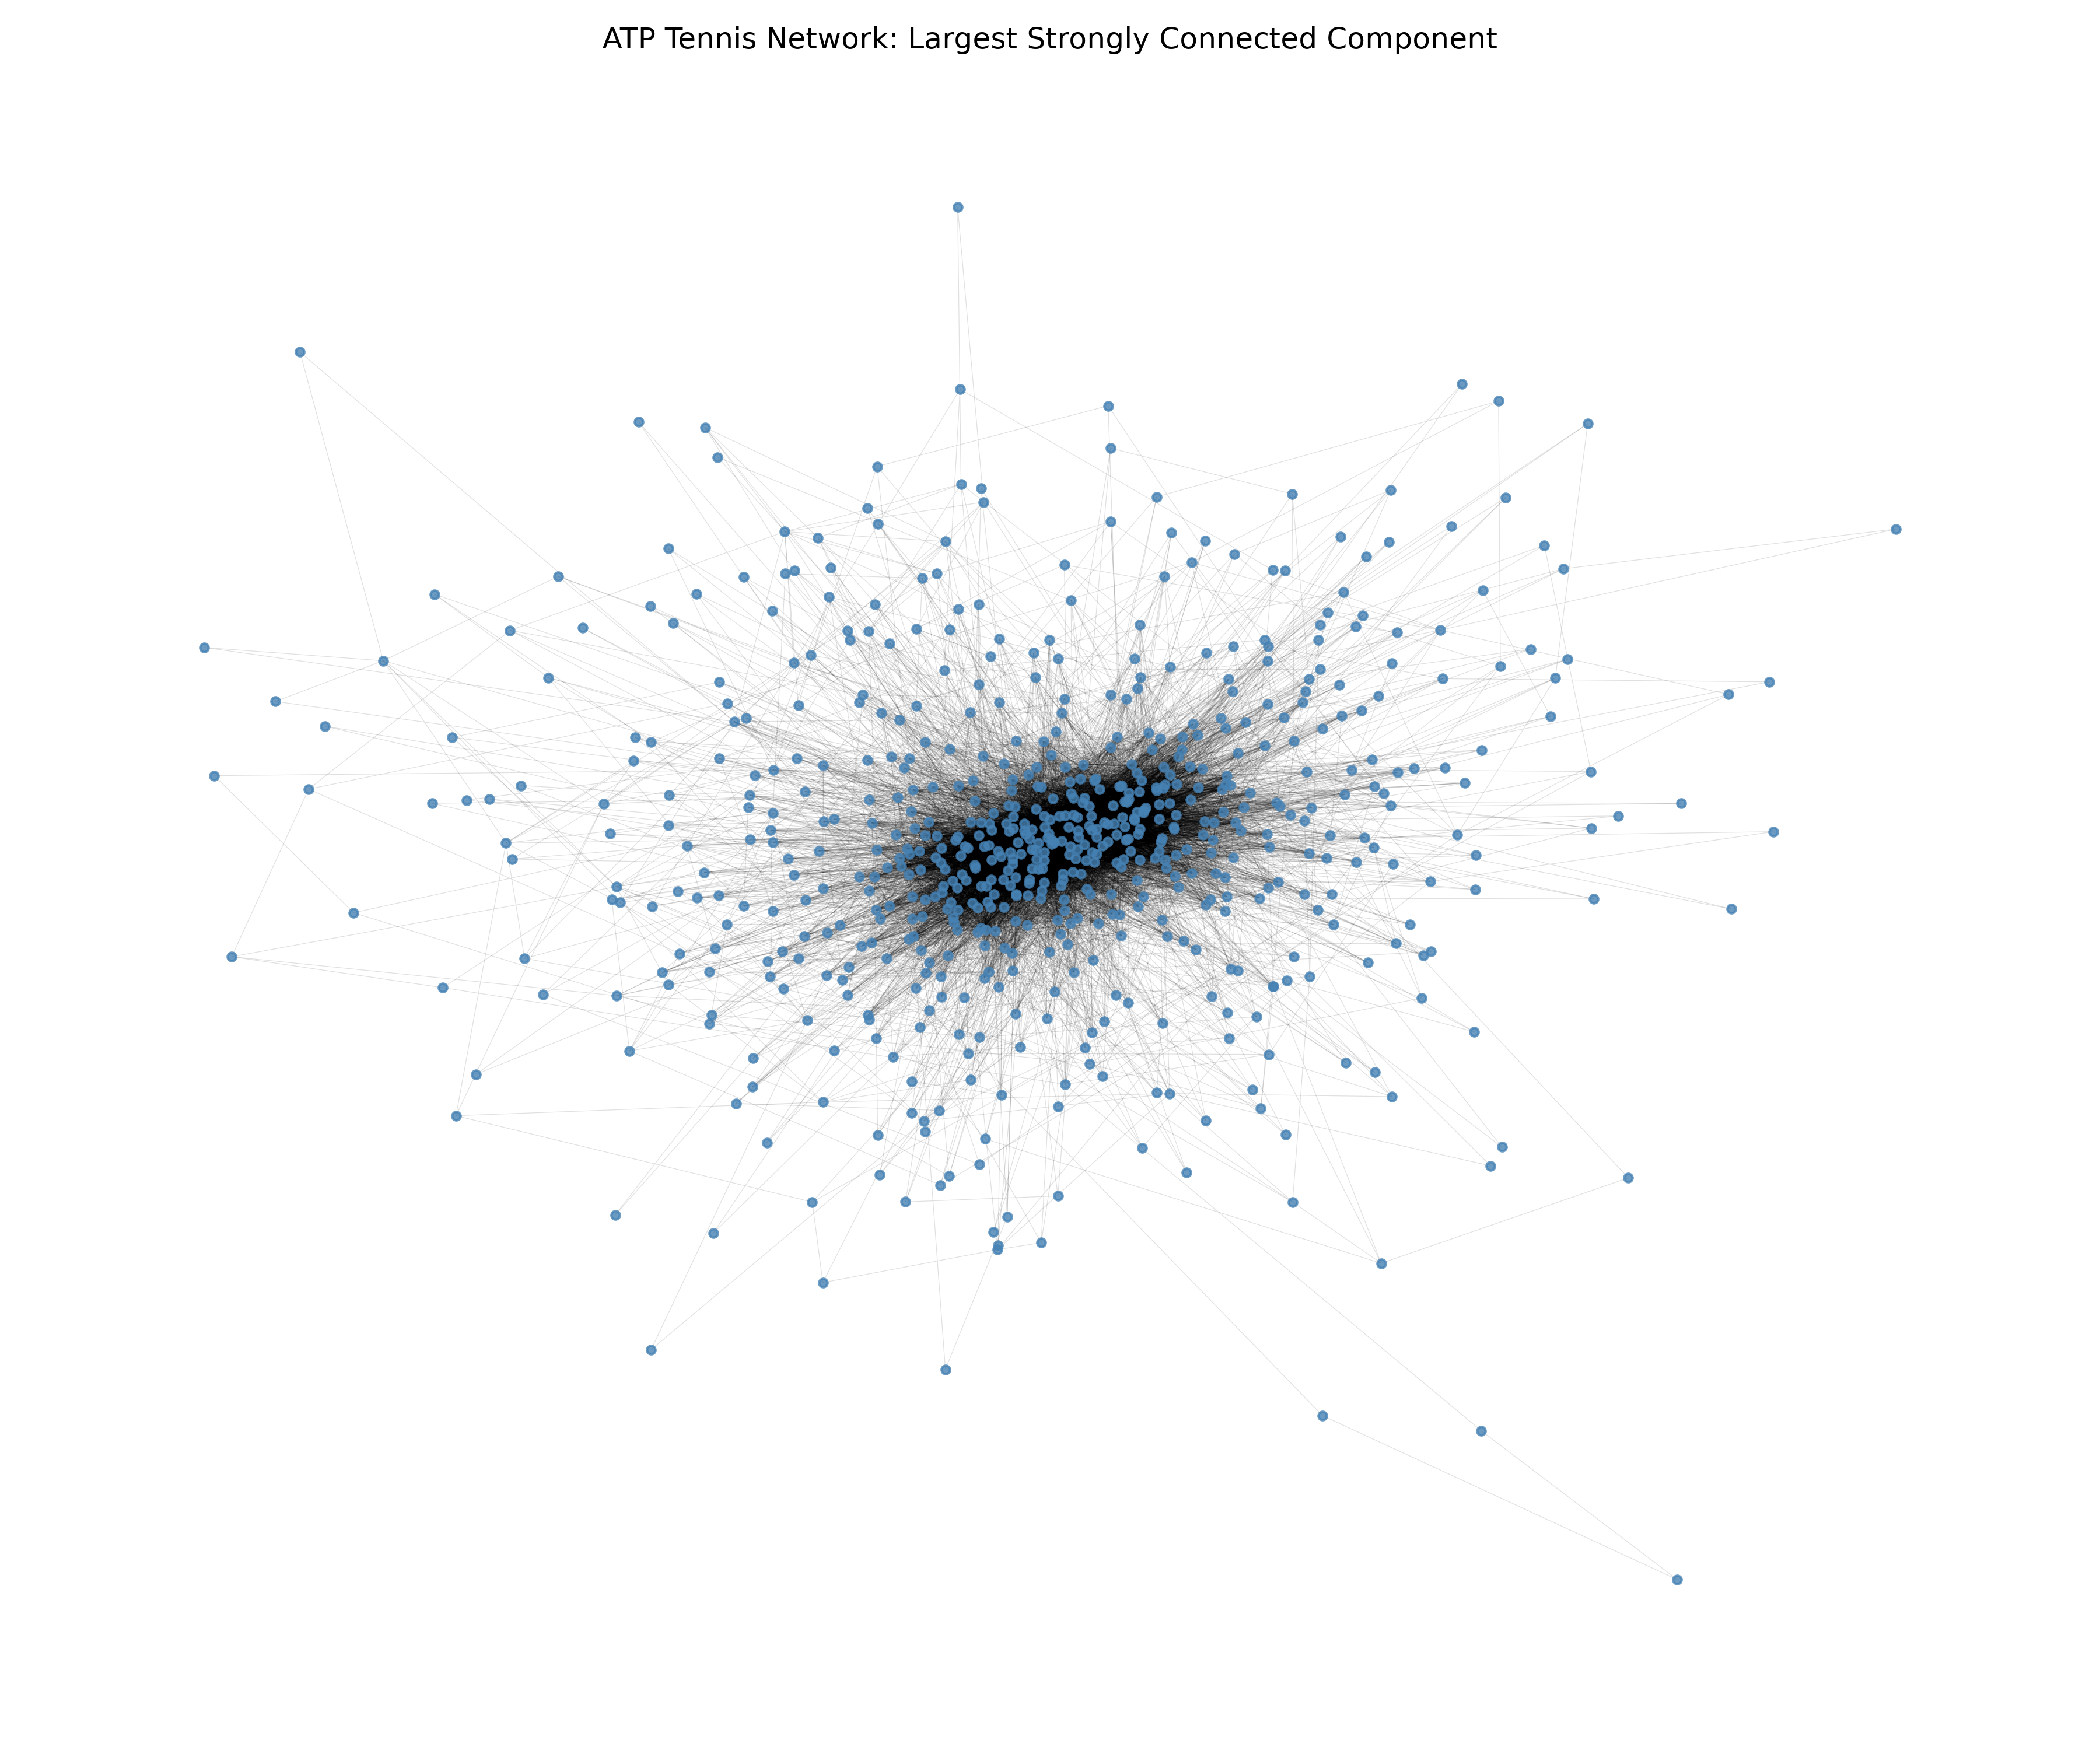

In [16]:
display(Image(filename=project_dir / "figures" / "largest_scc_network.png", width=650))

### Check the handoff to Task 3

We compare our rebuilt matrices with the saved project matrices used by Tasks 3 and 4.

In [17]:
with np.load(data_dir / "matrices.npz") as saved_matrices:
    saved_A, saved_P = saved_matrices["A"], saved_matrices["P"]

In [18]:
assert np.array_equal(A, saved_A), "The rebuilt A differs from the saved adjacency matrix."
print("Pass: the rebuilt adjacency matrix matches the project file.")

Pass: the rebuilt adjacency matrix matches the project file.


In [19]:
assert np.allclose(P, saved_P, atol=1e-12, rtol=0), "The rebuilt P differs from the saved transition matrix."
print("Pass: the rebuilt transition matrix matches the project file.")

Pass: the rebuilt transition matrix matches the project file.


## Task 2 · Examine the original graph and predict

We use the original match arrows in A for this task. The uniform rows added to P are rules of the walk and do not count as match results.

In [20]:
G = nx.from_numpy_array(A, create_using=nx.DiGraph)
components, closed = inspect_components(G)
size_counts = Counter(map(len, components))

print(f"Strongly connected components: {len(components)}")
print(f"Component sizes and counts: {sorted(size_counts.items())}")
print(f"Closed components: {len(closed)}")
print(f"Closed components with more than one player: {sum(len(group) > 1 for group in closed)}")
print(f"Dangling players: {np.count_nonzero(dangling)}")

Strongly connected components: 506


Component sizes and counts: [(1, 503), (3, 1), (4, 1), (681, 1)]
Closed components: 63
Closed components with more than one player: 0
Dangling players: 63


### Interpret the components and dangling players

The original graph has **506 strongly connected components**. The largest contains **681 players**, each of whom can reach every other player in that component by following directed match arrows, possibly through intermediaries. Two smaller components contain 3 and 4 players, and there are 503 singletons.

A **dangling player** has no outgoing match arrows. A **closed component** has no outgoing arrows to players outside it. In this dataset the 63 closed components are all singleton dangling players, and there are no closed components containing more than one player. The uniform rows in P let the walker leave those original singleton traps.

In [21]:
closed_players = {player for group in closed for player in group}
assert all(len(group) == 1 for group in closed) and closed_players == set(np.flatnonzero(dangling)), "The closed components differ from the dangling singletons."
print("Pass: the closed components of the match graph are exactly the dangling singletons.")

Pass: the closed components of the match graph are exactly the dangling singletons.


### Verify two directed cycles

Djokovic can return to himself along Djokovic → Nadal → Djokovic or Djokovic → Zverev → Federer → Djokovic. The arrows show that two- and three-step returns are possible. We revisit those return lengths in Task 4 when we examine periodicity in the completed walk.

In [22]:
cycle_names = (
    ("Novak Djokovic", "Rafael Nadal", "Novak Djokovic"),
    ("Novak Djokovic", "Alexander Zverev", "Roger Federer", "Novak Djokovic"),
)
for cycle in cycle_names:
    cycle_ids = [player_ids[name] for name in cycle]
    assert all(G.has_edge(i, j) for i, j in zip(cycle_ids, cycle_ids[1:])), f"Missing match arrow in {cycle}."
    print(" → ".join(cycle))

Novak Djokovic → Rafael Nadal → Novak Djokovic
Novak Djokovic → Alexander Zverev → Roger Federer → Novak Djokovic


### Make a prediction from the arrows

We predict that **Alexander Zverev** will rank highly. He has the most incoming arrows: 204 different opponents lost to him. These are opportunities for a walker to reach him. We save this prediction to compare with the rankings, which also depend on where the incoming probability comes from.

In [23]:
in_degree = A.sum(axis=0)
in_degree_table = nodes[["node_id", "label"]].copy()
in_degree_table["distinct opponents beaten"] = in_degree
display(in_degree_table.nlargest(5, "distinct opponents beaten"))

,node_id,label,distinct opponents beaten
0,0,Alexander Zverev,204
585,585,Taylor Fritz,189
130,130,Novak Djokovic,184
436,436,Daniil Medvedev,180
568,568,Andrey Rublev,179


### Choose two starting players

We chose **Novak Djokovic (ID 130)** because he belongs to the 681-player component and his first move follows recorded match links. We chose **Rohan Bopanna (ID 8)** because he has no outgoing match links and his first move uses the uniform row of P. These are two structurally different starts for the original walk.

In [24]:
for name in STARTING_PLAYERS:
    player = player_ids[name]
    print(f"{name} (ID {player}): out-degree {out_degree[player]}, in largest component: {player in components[0]}")

Novak Djokovic (ID 130): out-degree 51, in largest component: True
Rohan Bopanna (ID 8): out-degree 0, in largest component: False


### Sources

- IE University. [*Network Centrality and PageRank Using Matrices in Python*](https://blackboard.ie.edu/ultra/courses/_161148_1/file/_3020218_1?courseId=_161148_1), §§ 2.1–2.2.
- Sackmann, Jeff. [*ATP Tennis Rankings, Results, and Stats*](https://github.com/JeffSackmann/tennis_atp). Tennis Abstract. The teaching team prepared the [course ATP dataset](https://github.com/daniprec/BAM-CPI-LA-Networks/tree/2109df87176f730065237d42f76675149ff98166/data/atp_tennis).
- The existing group script supplies the full-component figure and the matrix archive.